# Vorhersage einer gedämpften schwingung mittels Reservoir Computing 
In diesem Projekt ist das Ziel gedämpfte schwingungen mittels Reservoir Computing vorherzusagen. 
Die Schwingungen werden von uns künstlich erzeugt.

---
## Aufbau

### Datenerzeugung 
Zuerst müssen verschiedene Gedämpfte schwingungen Erzeugt werden welche man für training braucht um sicher zu gehen das alle gewünschten bereiche abgedeckt sind. Test daten können einfach.  
  
y(t) = A · e^(-αt) · sin(ωt + φ)

A = Amplitude  
α = Dämpfungskonstante  
ω = Kreisfrequenz  
φ = Phase  

### Netzewerk erstellen 


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os




In [ ]:


def generate_diverse_oscillations(n=25):
    """Generiert n Schwingungen mit guter Parameterabdeckung"""
    
    oscillations = []
    
    # Kombiniere verschiedene Bereiche
    for i in range(n):
        # Amplitude: Gleichmäßig verteilt
        A = 0.5 + (1.5 / n) * i + np.random.uniform(-0.1, 0.1)
        
        # Dämpfung: Mische schwach/mittel/stark
        if i % 3 == 0:
            α = np.random.uniform(0.01, 0.05)  # schwach
        elif i % 3 == 1:
            α = np.random.uniform(0.05, 0.10)  # mittel
        else:
            α = np.random.uniform(0.10, 0.15)  # stark
        
        # Frequenz: Gleichmäßig verteilt
        ω = (1.0 + (3.0 / n) * i) * np.pi + np.random.uniform(-0.2, 0.2) * np.pi
        
        # Phase: Random
        φ = np.random.uniform(0, 2*np.pi)
        
        t = np.linspace(0, 20, 1000)
        y = A * np.exp(-α * t) * np.sin(ω * t + φ)
        
        oscillations.append({
            't': t,
            'y': y,
            'params': {'A': A, 'α': α, 'ω': ω, 'φ': φ}
        })
    
    return oscillations

oscillations = generate_diverse_oscillations(25)

print("Generated 25 random oscillations with varying parameters.")

if not os.path.exists('data'):
    os.makedirs('data')
    np.save('data/oscillations.npy', oscillations)
else:
    np.save('data/oscillations.npy', oscillations)



Generated 25 random oscillations with varying parameters.


In [ ]:
def generate_test_oscillations(n=25, seed=99):
    """
    Generiert n Test-Schwingungen vollständig zufällig.

    Gleiche Wertebereiche wie Trainingsdaten, aber rein zufällig
    (kein strukturiertes Abtasten des Parameterraums).
    seed=99 → reproduzierbar und verschieden von den Trainingsdaten.
    """
    rng = np.random.RandomState(seed)
    oscillations_test = []

    for i in range(n):
        # Alle Parameter vollständig zufällig aus den gleichen Bereichen
        A = rng.uniform(0.5, 2.0)
        α = rng.uniform(0.01, 0.15)
        ω = rng.uniform(1.0, 4.0) * np.pi
        φ = rng.uniform(0, 2 * np.pi)

        t = np.linspace(0, 20, 1000)
        y = A * np.exp(-α * t) * np.sin(ω * t + φ)

        oscillations_test.append({
            't': t,
            'y': y,
            'params': {'A': A, 'α': α, 'ω': ω, 'φ': φ}
        })

    return oscillations_test

oscillations_test = generate_test_oscillations(25)

print(f"Testdaten generiert: {len(oscillations_test)} Schwingungen")
print(f"Beispiel-Parameter: {oscillations_test[0]['params']}")
if not os.path.exists('data'):
    os.makedirs('data') 
    np.save('data/oscillations_test.npy', oscillations_test)
else: 
    np.save('data/oscillations_test.npy', oscillations_test)
print("Testdaten gespeichert unter: data/oscillations_test.npy")

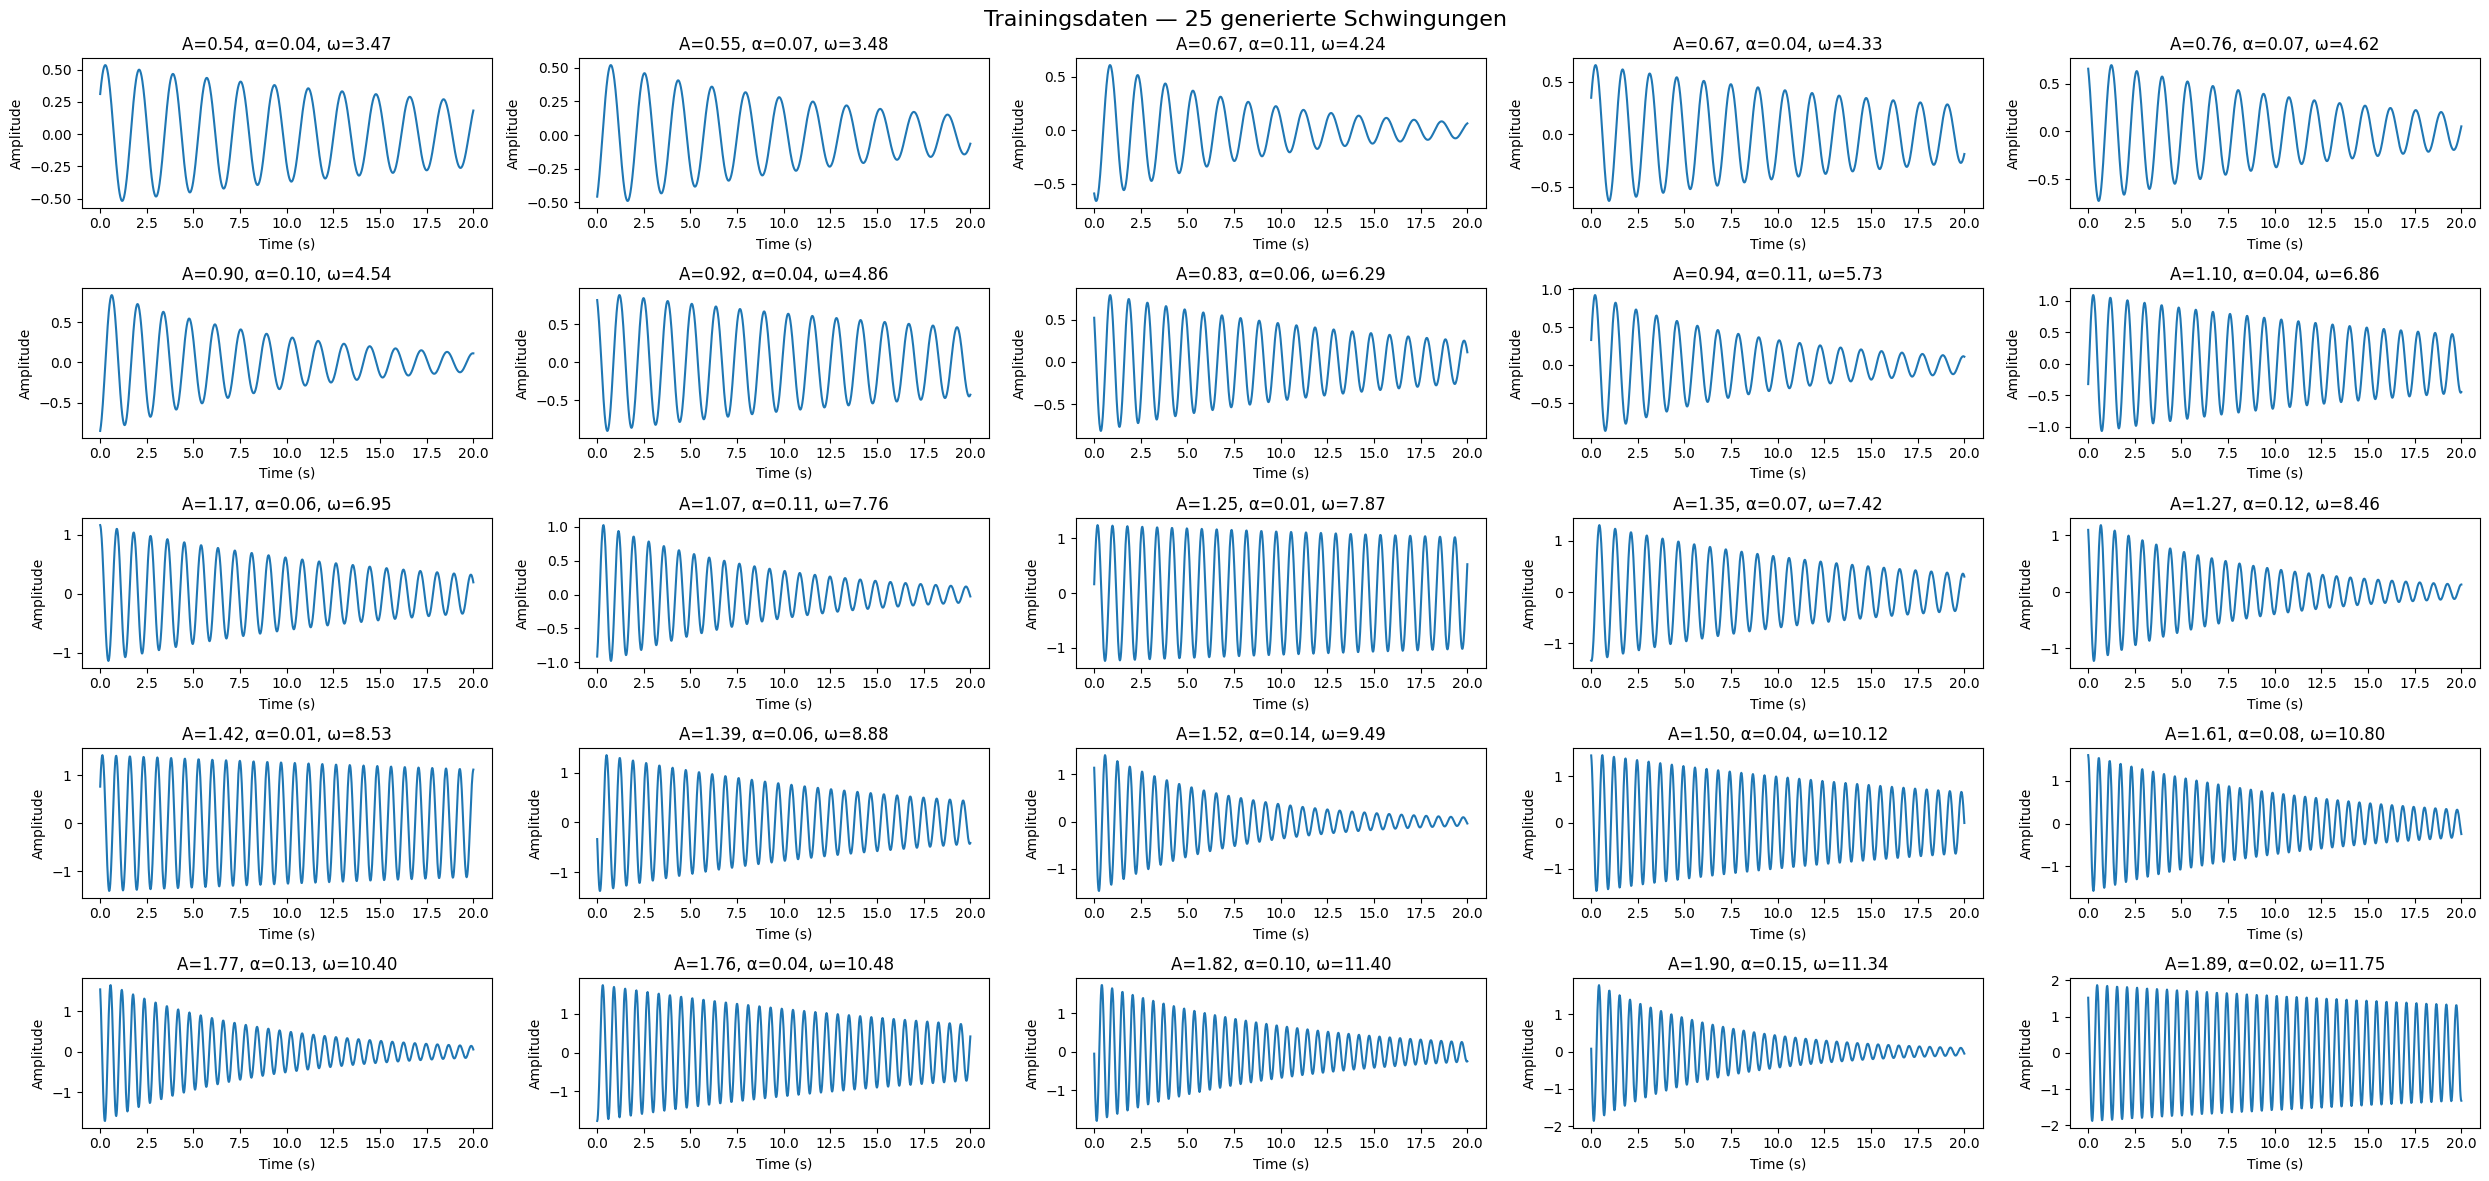

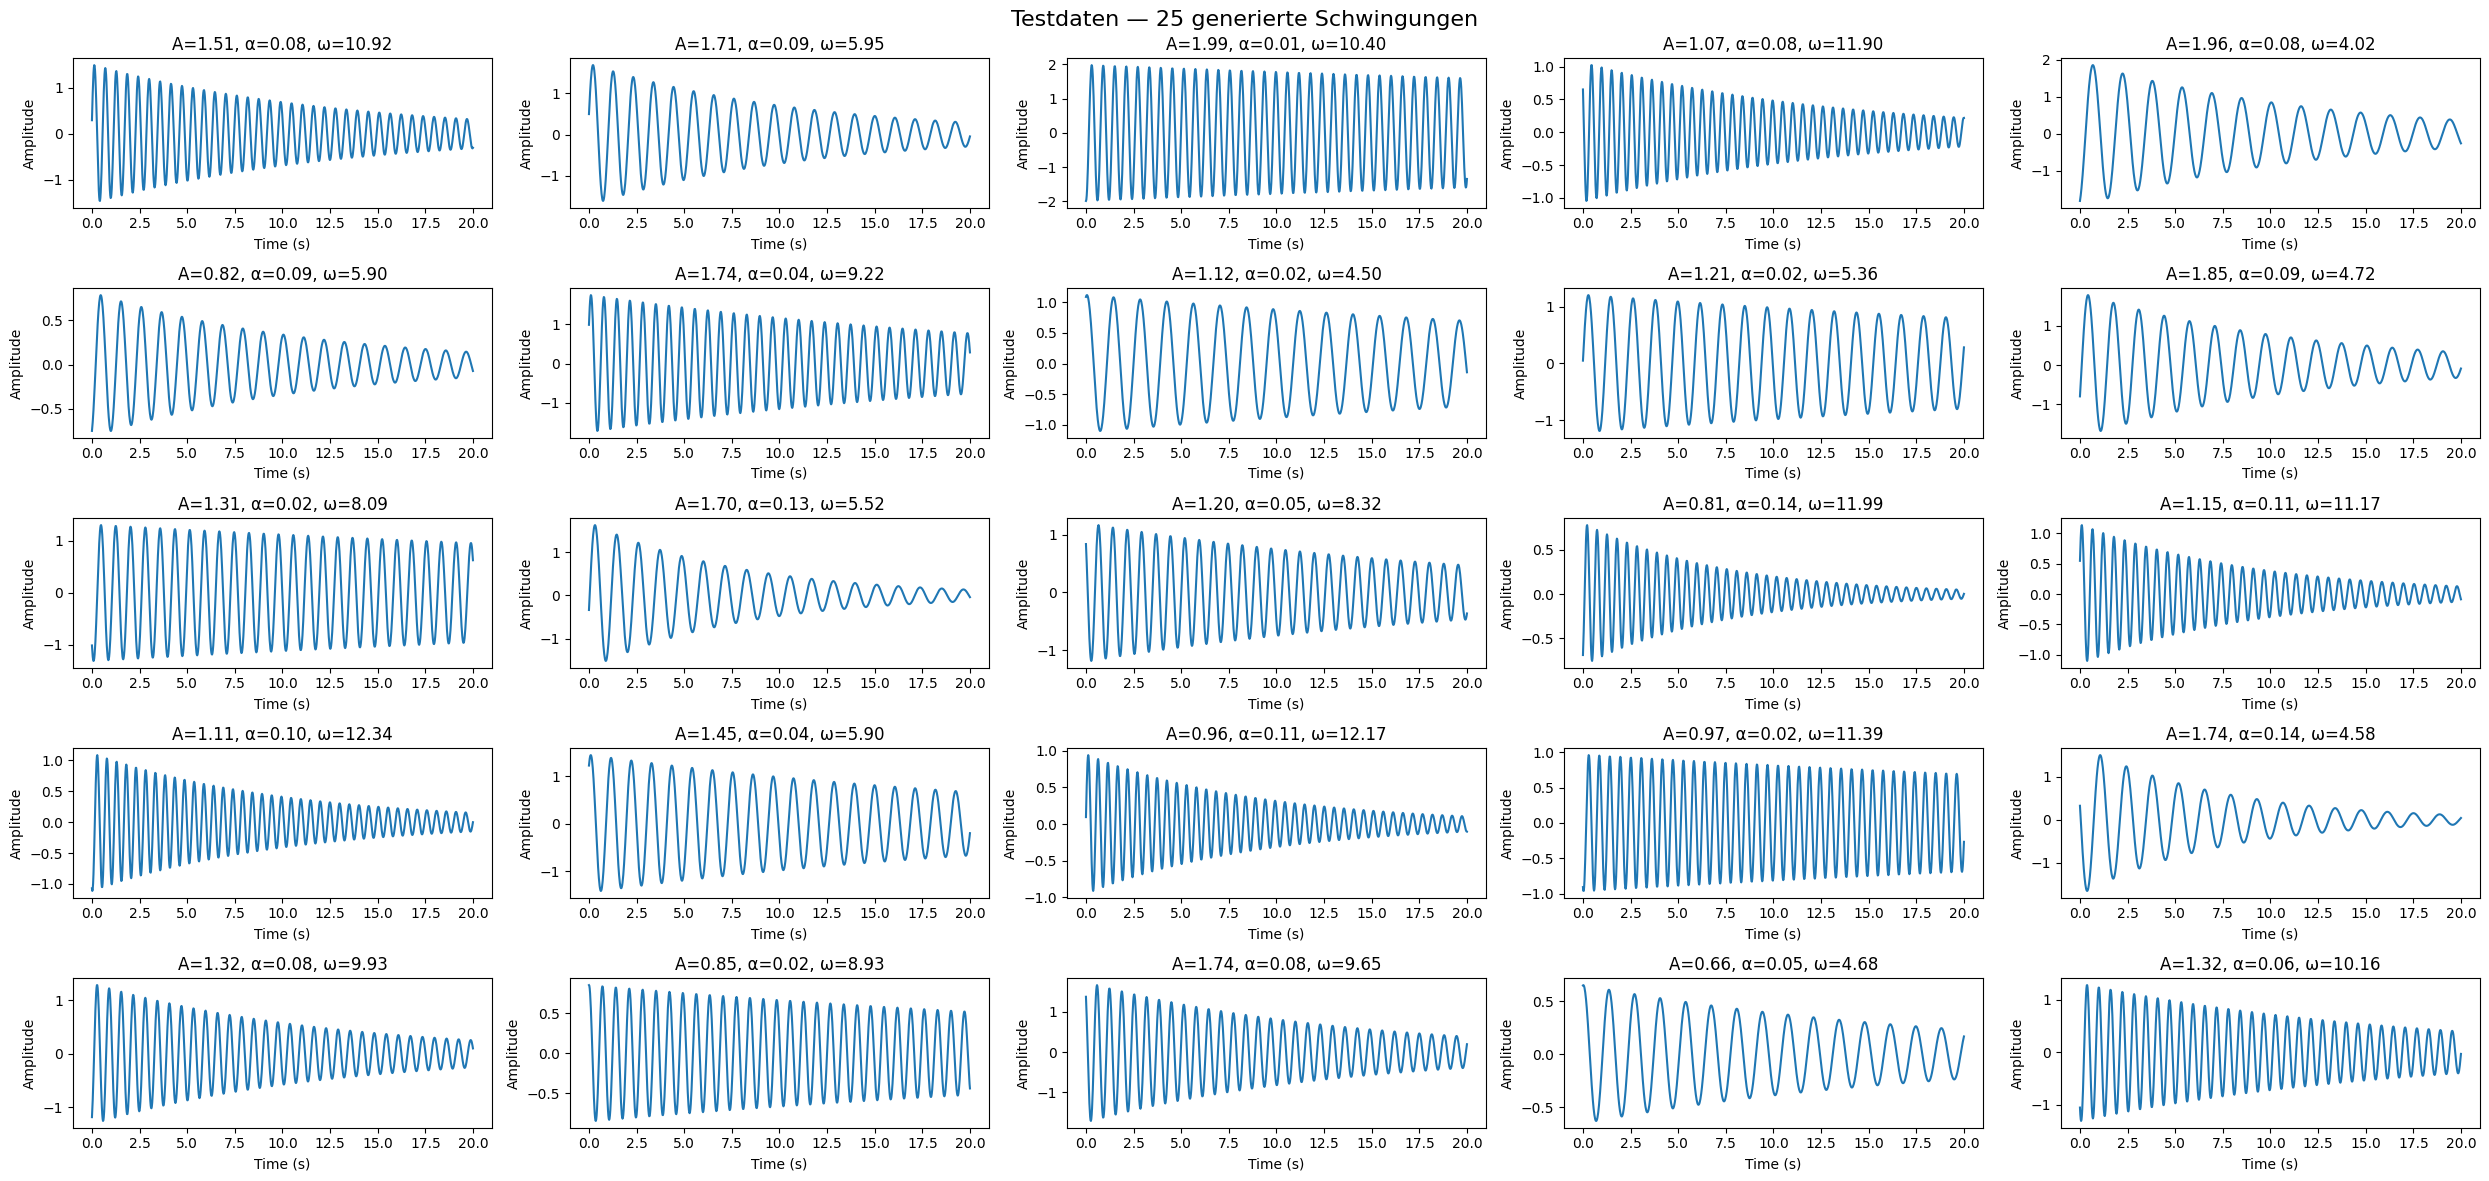

In [36]:
def plot_oscillations(oscillations, testdata: bool = False):
    """Plottet die generierten Schwingungen"""
    fig, axes = plt.subplots(5, 5, figsize=(25, 12))
    if testdata:
        fig.suptitle("Testdaten — 25 generierte Schwingungen", fontsize=16)
    else:
        fig.suptitle("Trainingsdaten — 25 generierte Schwingungen", fontsize=16)
    axes = axes.flatten()
    
    for i, osc in enumerate(oscillations):
        axes[i].plot(osc['t'], osc['y'])
        axes[i].set_title(f"A={osc['params']['A']:.2f}, α={osc['params']['α']:.2f}, ω={osc['params']['ω']:.2f}")
        axes[i].set_xlabel('Time (s)')
        axes[i].set_ylabel('Amplitude')
    
    plt.tight_layout()
    plt.show()

plot_oscillations(oscillations)
plot_oscillations(oscillations_test, True)

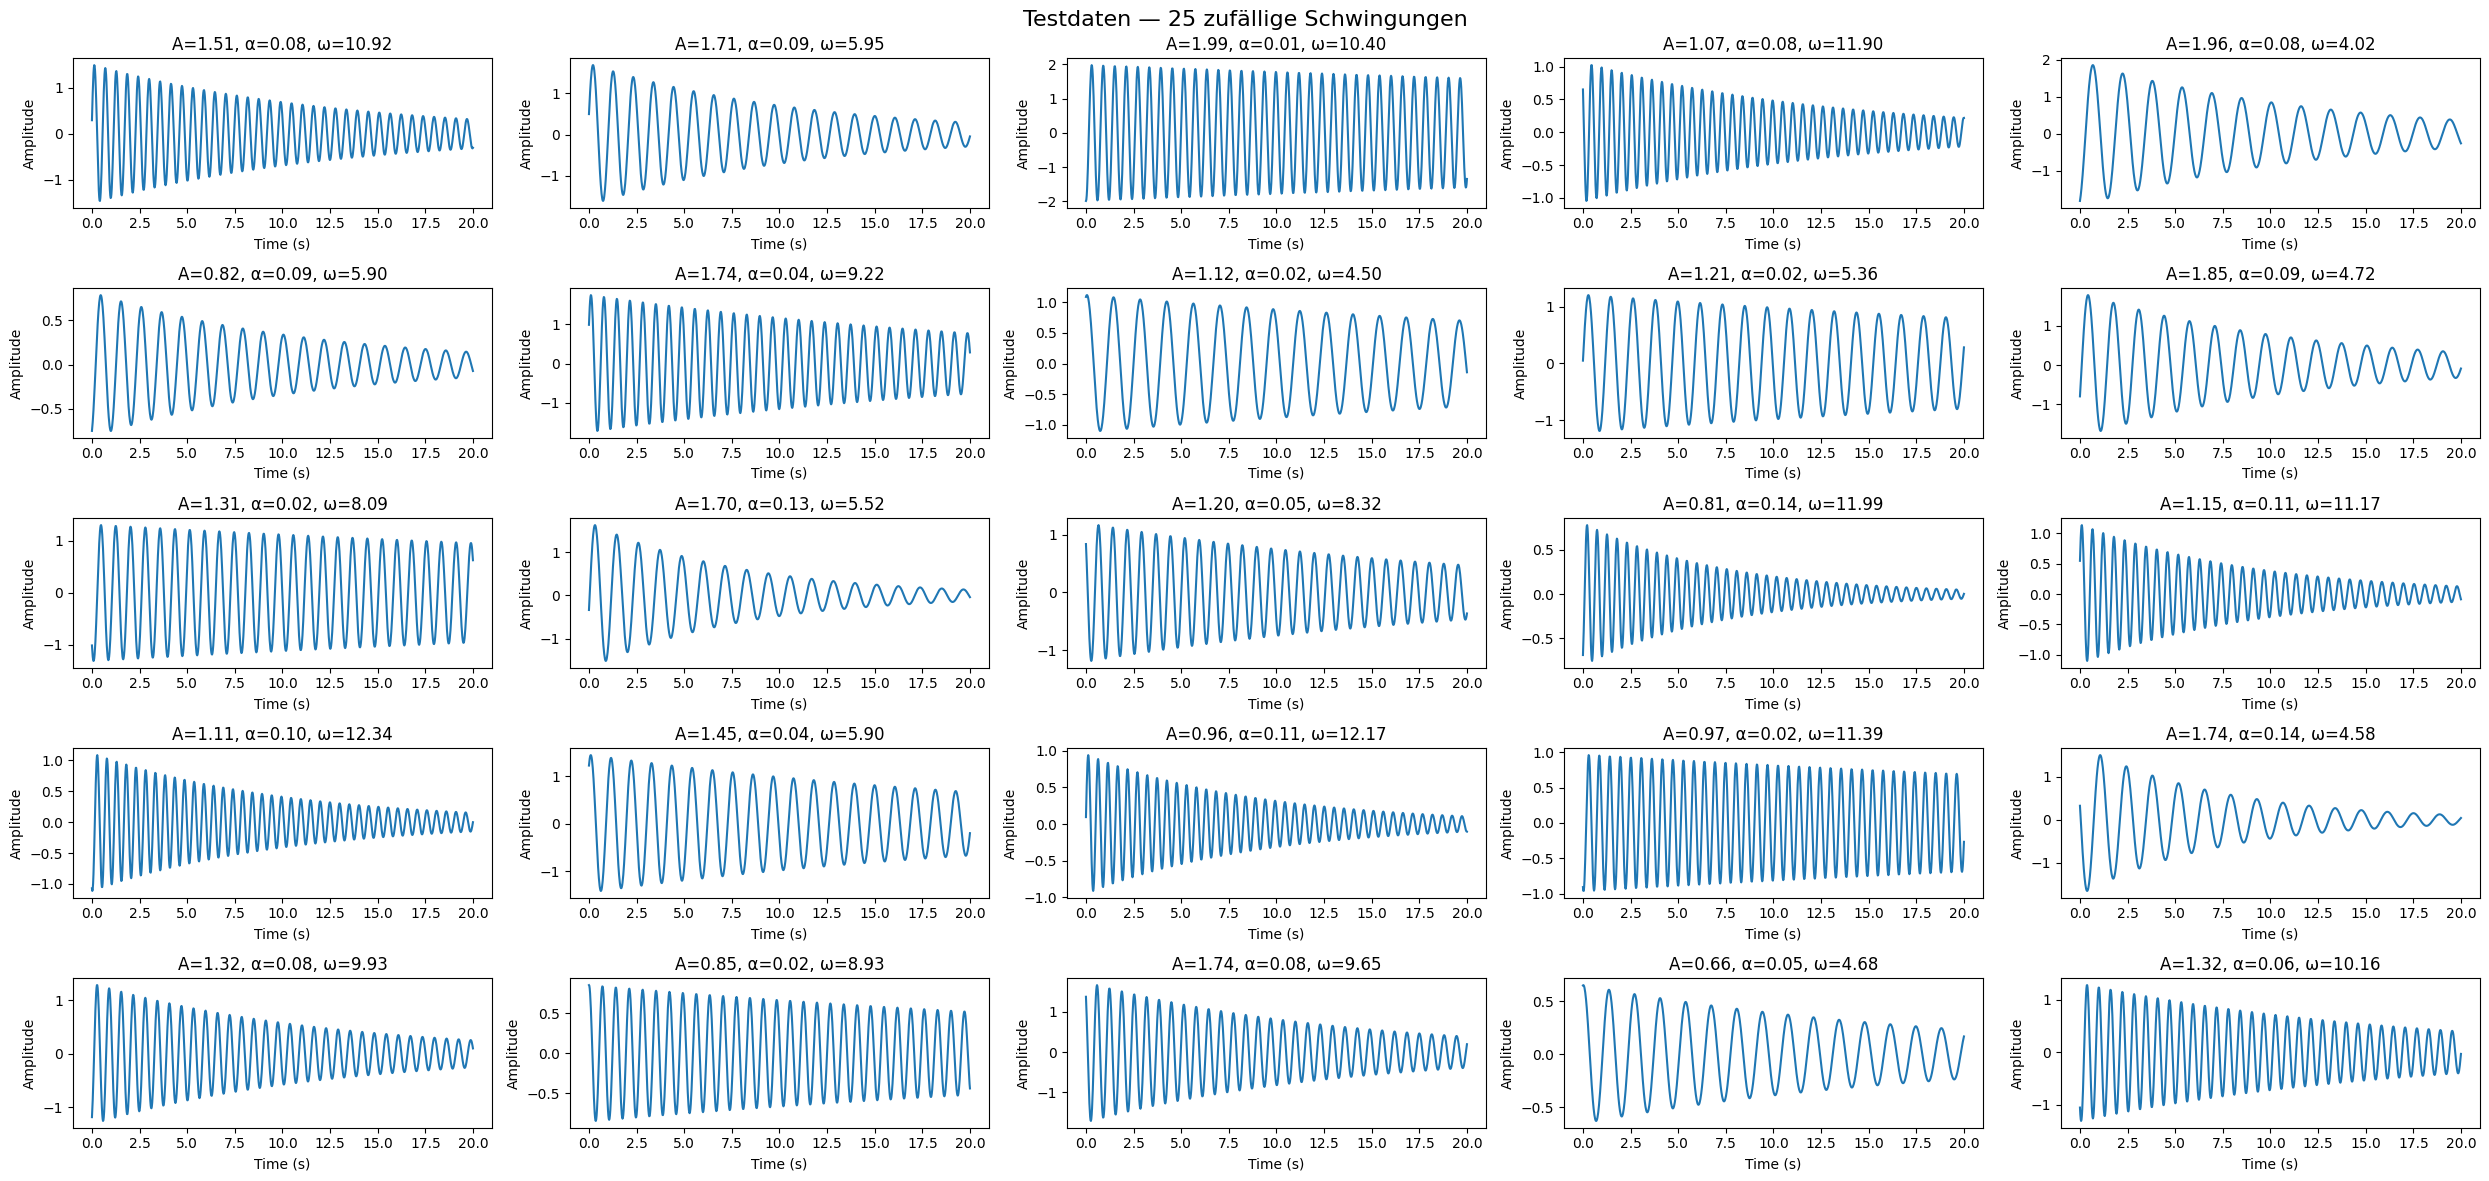

In [28]:
fig, axes = plt.subplots(5, 5, figsize=(25, 12))
fig.suptitle("Testdaten — 25 zufällige Schwingungen", fontsize=16)
axes = axes.flatten()

for i, osc in enumerate(oscillations_test):
    axes[i].plot(osc['t'], osc['y'])
    axes[i].set_title(f"A={osc['params']['A']:.2f}, α={osc['params']['α']:.2f}, ω={osc['params']['ω']:.2f}")
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

Testdaten gespeichert unter: data/oscillations_test.npy
